In [502]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="darkgrid")
RANDOM_STATE = 1

In [503]:
diabetes = pd.read_csv("datasets/diabetes.csv")
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


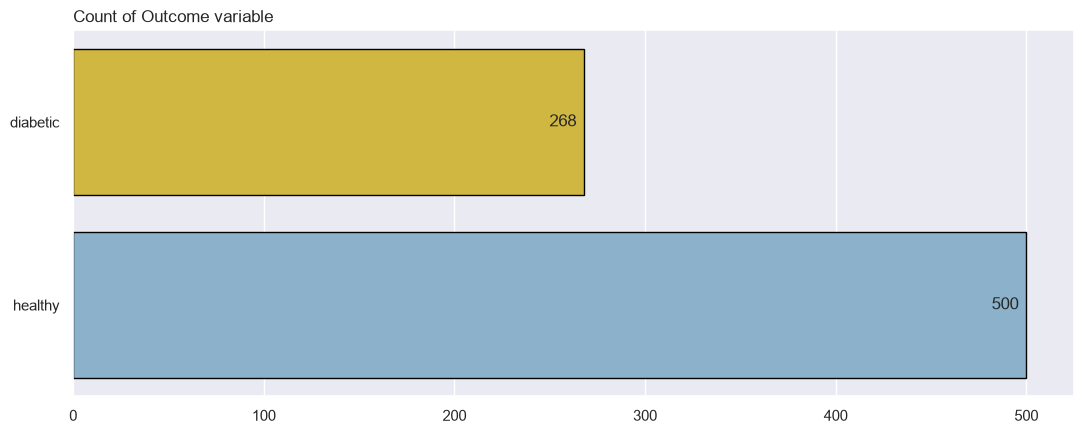

In [504]:
counts = diabetes["Outcome"].map({0: "healthy", 1: "diabetic"}).value_counts().reindex(["diabetic", "healthy"], fill_value=0).rename_axis("Outcome").reset_index(name="Count")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=counts, x="Count", y="Outcome", hue="Outcome",
    palette={"diabetic": "#E8C629", "healthy": "#80B5D5"},
    dodge=False,
    edgecolor="black",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        label_type="edge",
        padding=-25
    )

ax.set_title("Count of Outcome variable", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [505]:
# Pregnancies -> تعداد بارداری‌ها
# Glucose -> قند خون
# BloodPressure -> فشار خون
# SkinThickness -> ضخامت چین پوستی
# Insulin -> انسولین
# BMI -> شاخص توده بدنی
# DiabetesPedigreeFunction -> شاخص سابقه خانوادگی دیابت
# Age -> سن
# Outcome -> نتیجه‌(دیابت دارد یا خیر)

(diabetes == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [506]:
zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
diabetes[zero_features] = diabetes[zero_features].replace(0, np.nan)
for feature in zero_features:
    stat = "median" if feature == "Insulin" else "mean"
    diabetes[feature] = diabetes.groupby("Outcome")[feature].transform(lambda s, stat=stat: s.fillna(getattr(s, stat)()))

((diabetes == 0) | diabetes.isna()).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [507]:
# EDA-derived features
diabetes["HighBloodPressure"] = (diabetes["BloodPressure"] > 80).astype(int)
diabetes["HighGlucose"] = (diabetes["Glucose"] > 105).astype(int)

diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,HighBloodPressure,HighGlucose
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1,0,1
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0,0,0
2,8,183.0,64.0,33.0,169.5,23.3,0.672,32,1,0,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,0,1


In [508]:
X = diabetes.copy()
y = X.pop("Outcome")

extended_features = list(X.columns)
normal_features = [f for f in extended_features if f not in ("HighBloodPressure", "HighGlucose")]
reduced_features = [f for f in normal_features if f not in ("SkinThickness", "DiabetesPedigreeFunction")]

In [509]:
SETUP_TITLES = {
    "extended": "all features + 2 new",
    "normal": "original 8 features",
    "reduced": "without SkinThickness, Pedigree & 2 new",
}


def make_split(features):
    X_train, X_test, y_train, y_test = train_test_split(X[features], y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
    scaler = MinMaxScaler()
    X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)
    X_test = pd.DataFrame(scaler.transform(X_test), columns=features, index=X_test.index)
    return X_train, X_test, y_train, y_test


splits = {
    "extended": make_split(extended_features),
    "normal": make_split(normal_features),
    "reduced": make_split(reduced_features),
}

{setup: (f"train={len(s[0])}", f"test={len(s[1])}") for setup, s in splits.items()}

{'extended': ('train=537', 'test=231'),
 'normal': ('train=537', 'test=231'),
 'reduced': ('train=537', 'test=231')}

In [510]:
def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=[0, 1], yticklabels=[0, 1], annot_kws={"size": 14})
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def get_metrics(y_true, y_pred, technique):
    return {
        "Classification Technique": technique,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

In [511]:
metrics = {"extended": [], "normal": [], "reduced": []}

def run_model(model, label):
    for setup, (X_train, X_test, y_train, y_test) in splits.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        plot_confusion_matrix(y_test, y_pred, title=f"{label} — {SETUP_TITLES[setup]}")
        metrics[setup].append(get_metrics(y_test, y_pred, label))


--- KNN (k=5) ---


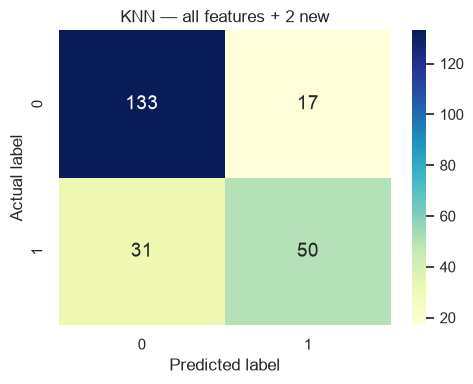

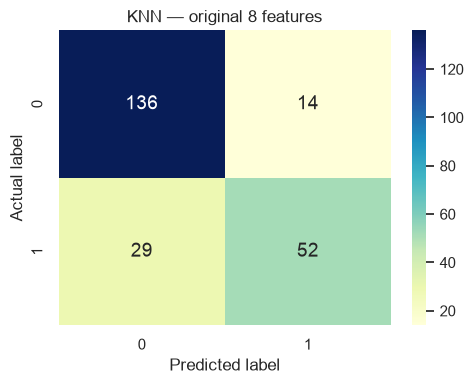

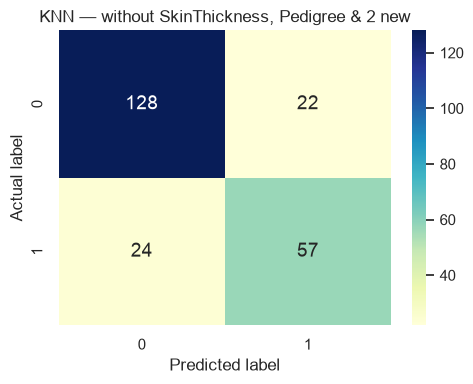

In [512]:
print("\n--- KNN (k=5) ---")
knn = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
run_model(knn, "KNN")


--- Random forests ---


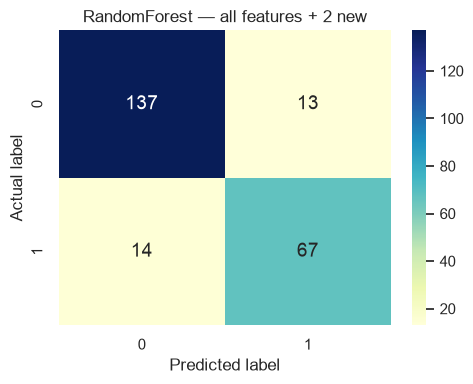

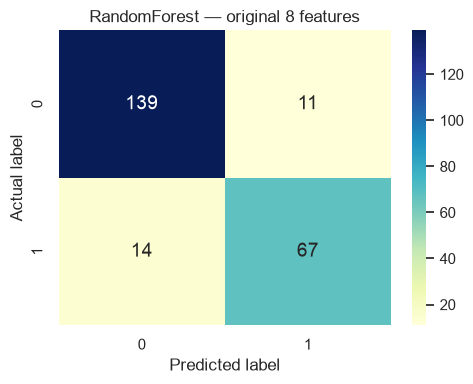

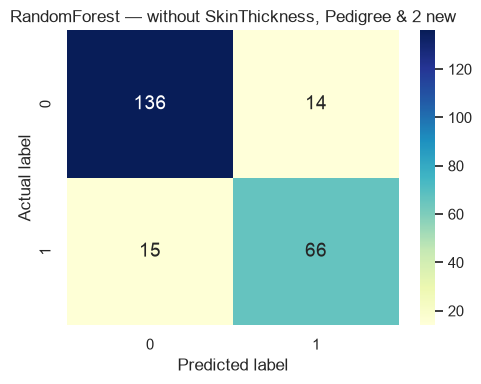

In [513]:
print("\n--- Random forests ---")
rf = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
run_model(rf, "RandomForest")


--- SVM ---


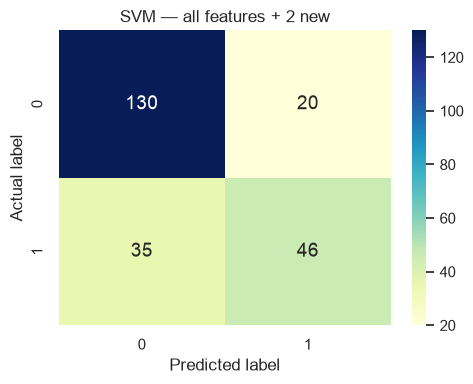

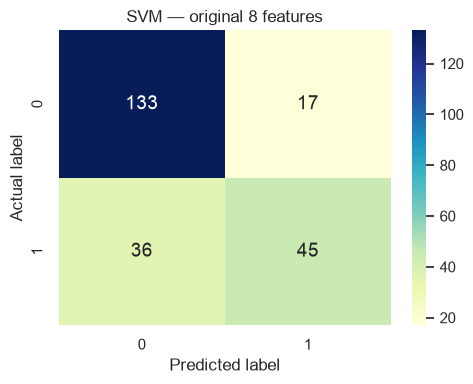

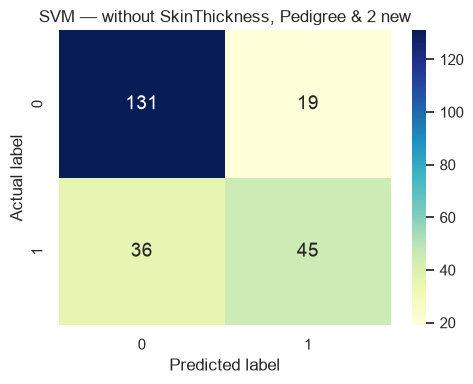

In [514]:
print("\n--- SVM ---")
svm = SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)
run_model(svm, "SVM")


--- ANN ---


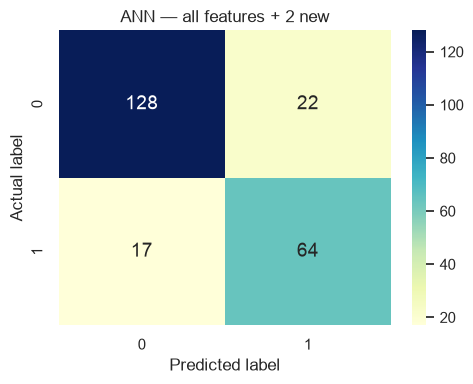

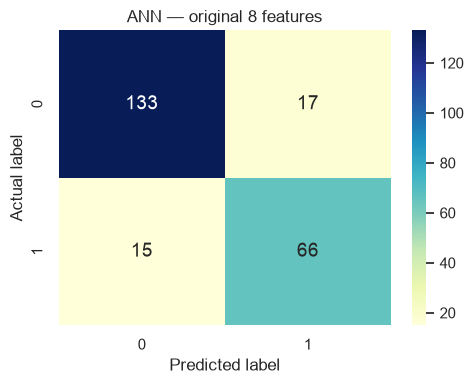

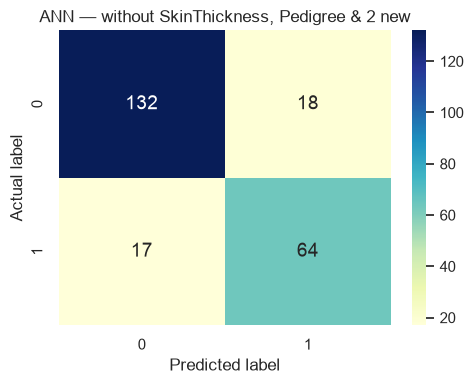

In [515]:
print("\n--- ANN ---")
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16, 8,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=RANDOM_STATE,
)
run_model(ann, "ANN")


--- Decision Tree ---


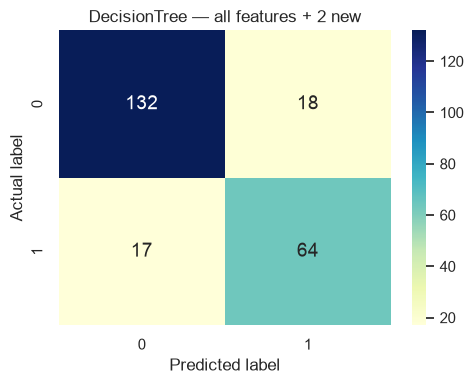

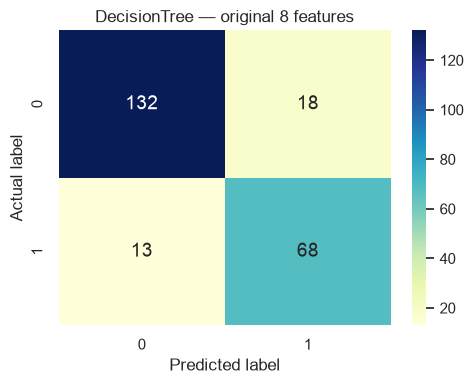

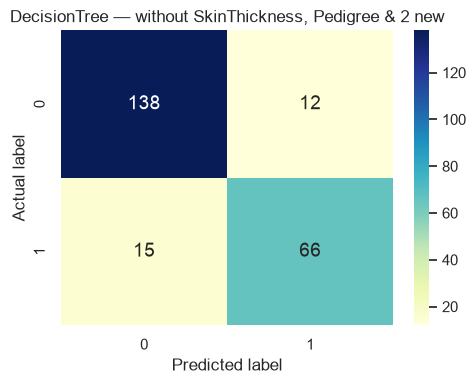

In [516]:
print("\n--- Decision Tree ---")
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)
run_model(dt, "DecisionTree")

In [517]:
results = {
    setup: pd.DataFrame(rows).set_index("Classification Technique")
    for setup, rows in metrics.items()
}

for setup, title in SETUP_TITLES.items():
    print(f"—— {title} ——")
    display(results[setup].style.format("{:.2%}"))
    print()

—— all features + 2 new ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,79.22%,74.63%,61.73%,67.57%
RandomForest,88.31%,83.75%,82.72%,83.23%
SVM,76.19%,69.70%,56.79%,62.59%
ANN,83.12%,74.42%,79.01%,76.65%
DecisionTree,84.85%,78.05%,79.01%,78.53%



—— original 8 features ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,81.39%,78.79%,64.20%,70.75%
RandomForest,89.18%,85.90%,82.72%,84.28%
SVM,77.06%,72.58%,55.56%,62.94%
ANN,86.15%,79.52%,81.48%,80.49%
DecisionTree,86.58%,79.07%,83.95%,81.44%



—— without SkinThickness, Pedigree & 2 new ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,80.09%,72.15%,70.37%,71.25%
RandomForest,87.45%,82.50%,81.48%,81.99%
SVM,76.19%,70.31%,55.56%,62.07%
ANN,84.85%,78.05%,79.01%,78.53%
DecisionTree,88.31%,84.62%,81.48%,83.02%


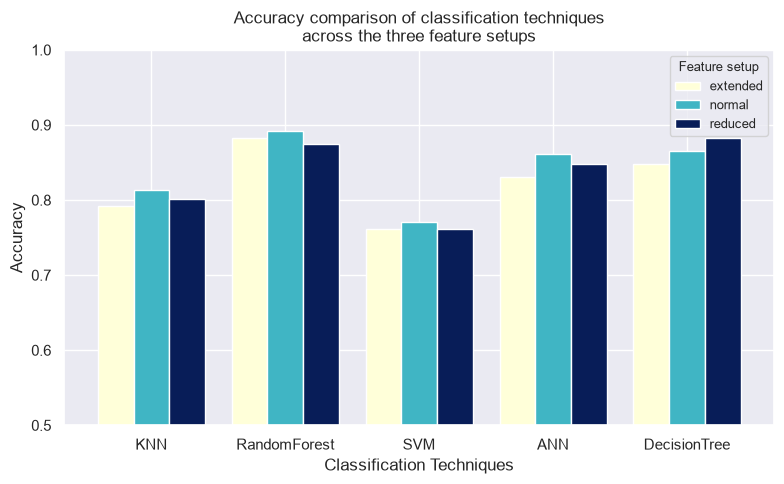

,extended,normal,reduced
Classification Technique,,,
KNN,79.22%,81.39%,80.09%
RandomForest,88.31%,89.18%,87.45%
SVM,76.19%,77.06%,76.19%
ANN,83.12%,86.15%,84.85%
DecisionTree,84.85%,86.58%,88.31%


In [518]:
accuracy = pd.DataFrame({setup: results[setup]["Accuracy"] for setup in results})

ax = accuracy.plot(kind="bar", figsize=(8, 5), ylim=(0.5, 1.0), colormap="YlGnBu", width=0.8)
ax.set_ylabel("Accuracy")
ax.set_xlabel("Classification Techniques")
ax.set_title("Accuracy comparison of classification techniques\nacross the three feature setups")
ax.legend(title="Feature setup", fontsize=9, title_fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

accuracy.style.format("{:.2%}")